In [ ]:
import pandas as pd
import os
import matplotlib.pyplot as mpl
from matplotlib.animation import FuncAnimation
#example change. Need to push to github
#fork workflow pull request.
#

print(os.getcwd())# Check CWD for file path
print(os.listdir())# Check inside


/Users/jimmynguyen/Documents/SportsAnalyticsFall2026/NFLData+Python
['football_player_tracking.csv', 'NFLPlayerData.ipynb', 'Data', 'SportsAnalytics.py']


In [ ]:
file_name = "football_player_tracking.csv" # Change to tracking_5_games.csv
df = pd.read_csv(file_name, nrows = 1000)

#perhaps run a monte carlo quickly.


In [ ]:
print(df.describe()) # Gives count, mean, std, etc etc.


            game_id  play_id        nfl_id    frame_id  \
count  1.000000e+02    100.0    100.000000  100.000000   
mean   2.023091e+09    101.0  44829.490000   18.570000   
std    0.000000e+00      0.0   1045.694863   12.046421   
min    2.023091e+09    101.0  43290.000000    1.000000   
25%    2.023091e+09    101.0  43290.000000    9.000000   
50%    2.023091e+09    101.0  44930.000000   17.000000   
75%    2.023091e+09    101.0  46137.000000   25.250000   
max    2.023091e+09    101.0  46137.000000   47.000000   

       absolute_yardline_number  player_weight           x           y  \
count                     100.0     100.000000  100.000000  100.000000   
mean                       42.0     205.180000   47.733300   18.603900   
std                         0.0      11.125891    8.742408    7.984985   
min                        42.0     196.000000   35.230000    2.830000   
25%                        42.0     196.000000   37.360000   12.655000   
50%                        42.0  

In [6]:
print("Shape")
print(df.shape) 

print("Columns")
print(df.columns)

print("head")
print(df.head())






Shape


NameError: name 'df' is not defined

In [40]:
print("info")
print(df.info())

info
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   game_id                   100 non-null    int64  
 1   play_id                   100 non-null    int64  
 2   player_to_predict         100 non-null    bool   
 3   nfl_id                    100 non-null    int64  
 4   frame_id                  100 non-null    int64  
 5   play_direction            100 non-null    str    
 6   absolute_yardline_number  100 non-null    float64
 7   player_name               100 non-null    str    
 8   player_height             100 non-null    str    
 9   player_weight             100 non-null    float64
 10  player_birth_date         78 non-null     str    
 11  player_position           100 non-null    str    
 12  player_side               100 non-null    str    
 13  player_role               100 non-null    str    
 14  x                

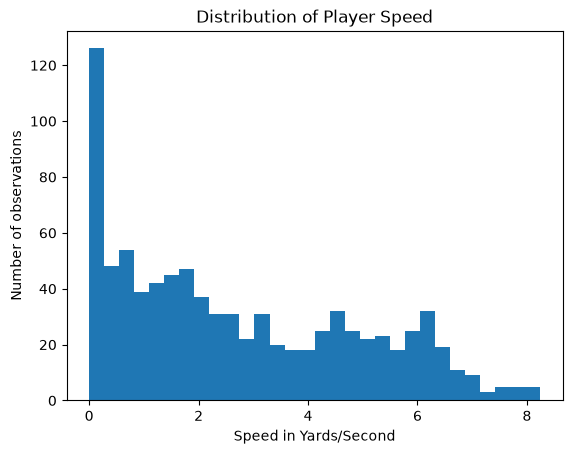

In [3]:
df["s"].describe() # We need units

mpl.hist(df["s"], bins=30)

mpl.xlabel("Speed in Yards/Second")
mpl.ylabel("Number of observations")
mpl.title("Distribution of Player Speed")

mpl.show()

##reconstruct/animate short window of live game

In [4]:
#game_id
#play_id
#frame_id
#nfl_id
#x
#y
#player_name
#player_position
#player_side
#player_role

#We need all frames belonging to one play

print(df[["game_id", "play_id"]].drop_duplicates())
#Returns game_id : 2023090700, play_id : 101. This is what I'll focus on
#Get first 1000 rows or extract game 2023090700 and all frames.
print(df["frame_id"].unique())
#we have 47 unique frames. Perhaps there are more past 100 rows. How do we get only what we need wihtout having to
#access the entire 5.4 million lines?







        game_id  play_id
0    2023090700      101
297  2023090700      194
758  2023090700      219
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47]


In [58]:
print(df["frame_id"].value_counts())

print(df["frame_id"].nunique()) # Returns number of unique values as an integer
#.unique returns actual unqiue frames. 


frame_id
1     35
2     35
3     35
4     35
5     35
6     35
7     35
8     35
9     35
10    35
11    35
12    35
13    35
14    35
15    34
16    34
17    34
18    25
19    25
20    25
21    25
22    25
23    25
24    25
25    25
26    22
27    16
28    16
29    16
30    16
31    16
32    16
33     8
34     8
35     8
36     8
37     8
38     8
39     8
40     8
41     8
42     3
43     3
44     3
45     3
46     3
47     3
Name: count, dtype: int64
47


In [6]:
print(df.groupby(["game_id", "play_id"]).size())

print(df[df["play_id"] == 101].shape)

#game_id : 2023090700  play_id : 101      rows 0-297
#.shape -- (297, 24)




game_id     play_id
2023090700  101        297
            194        461
            219        242
dtype: int64
(297, 24)


In [5]:
play = df[(df["game_id"] == 2023090700) & (df["play_id"]==101)]

print(play.shape)
#returns 297, 24. Perfect.
print(play['frame_id'].unique()) 
print(play['frame_id'].nunique())
#47 unique frames.

play.groupby('frame_id').size() ##notice that there are 9 frames for 1-26ish, and 27-47 have 3 frames each.











(297, 24)
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47]
47


frame_id
1     9
2     9
3     9
4     9
5     9
6     9
7     9
8     9
9     9
10    9
11    9
12    9
13    9
14    9
15    9
16    9
17    9
18    9
19    9
20    9
21    9
22    9
23    9
24    9
25    9
26    9
27    3
28    3
29    3
30    3
31    3
32    3
33    3
34    3
35    3
36    3
37    3
38    3
39    3
40    3
41    3
42    3
43    3
44    3
45    3
46    3
47    3
dtype: int64

In [7]:
#First Frame Test, Set up First Frame snapshot

first_frame = play["frame_id"].min() ## first value, for first frame.
selected_frame = play[play['frame_id'] == first_frame] # Give me the rows where frame_id equals first_frame.
#Notice the == instead of =. Produces bool value.

#All has Resolved below:
#play[play['frame_id'] == play["frame_id"].min()] This works, but is long.
#cant you just do 
# selected_frame = play[play['frame_id'].min()] -- No, it wouldnt work. It is play[10]. returns error

print(selected_frame[['nfl_id', 'player_name', 'player_position', 'player_side', 'x', 'y']]) #First frame snapshot



     nfl_id        player_name player_position player_side      x      y
0     43290         Jared Goff              QB     Offense  37.36  30.07
26    44930      Josh Reynolds              WR     Offense  41.03  12.17
73    46137        Justin Reid              SS     Defense  51.32  20.69
120   52546     L'Jarius Sneed              CB     Defense  44.42  11.69
167   53487        Nick Bolton             MLB     Defense  44.56  27.66
193   53541  Amon-Ra St. Brown              WR     Offense  40.61  19.12
219   53959       Brock Wright              TE     Offense  40.91  35.14
245   54486     Trent McDuffie              CB     Defense  43.61  39.42
271   54527         Bryan Cook              FS     Defense  52.33  36.94


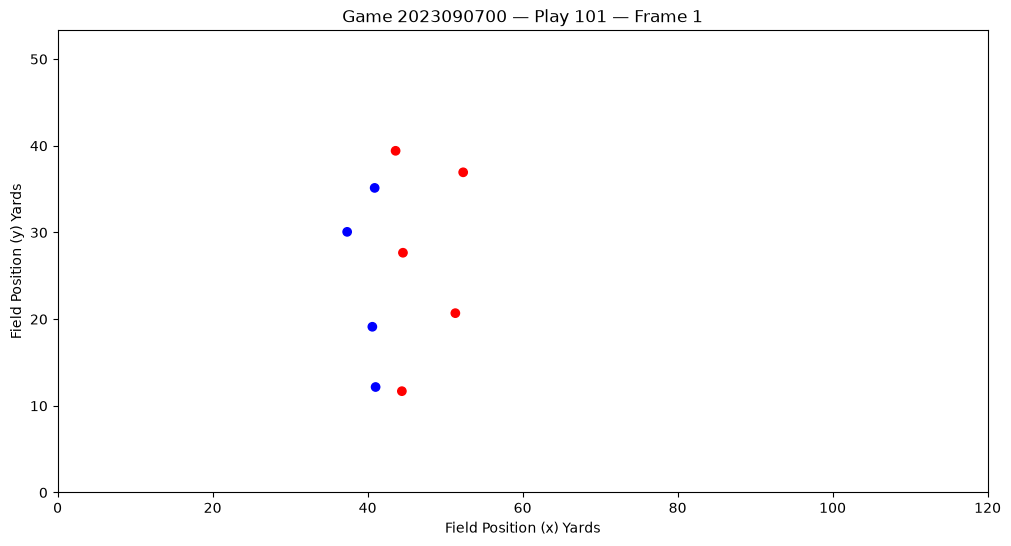

In [8]:
#First Frame visualization

colors = selected_frame['player_side'].map({'Offense': 'blue','Defense': 'red'})
# pandas creates the color list in the same row order as selected_frame. Thus able to match up in c=colors.
mpl.figure(figsize=(12, 6))

mpl.scatter(selected_frame['x'], selected_frame['y'], c=colors) ## Selected frame refers to the first frame. This is
#the x and y values for that first frame. On its own, it doesnt mean anything. We need to plot players.
# How does .scatter know that 37.36 for x is with 30.07 for 7?
#Moreover, what units are these X and Y's in?
mpl.xlim(0, 120)
mpl.ylim(0, 53.3) ## the NFL Field dimensions. Approx 53 yds wide, 120 yds long. This makes the plot
#appear like a field by setting how big the graph should be.
mpl.xlabel('Field Position (x) Yards')
mpl.ylabel('Field Position (y) Yards')
mpl.title(f'Game 2023090700 — Play 101 — Frame {first_frame}') # first_frame evaluates to 1, perfect.

mpl.show()
# Each Dot represents a football player. I need to plot Positions on each.

# So far :
#CSV -- Pandas -- Select one play -- Select one frame --x/y coords -- MPL.




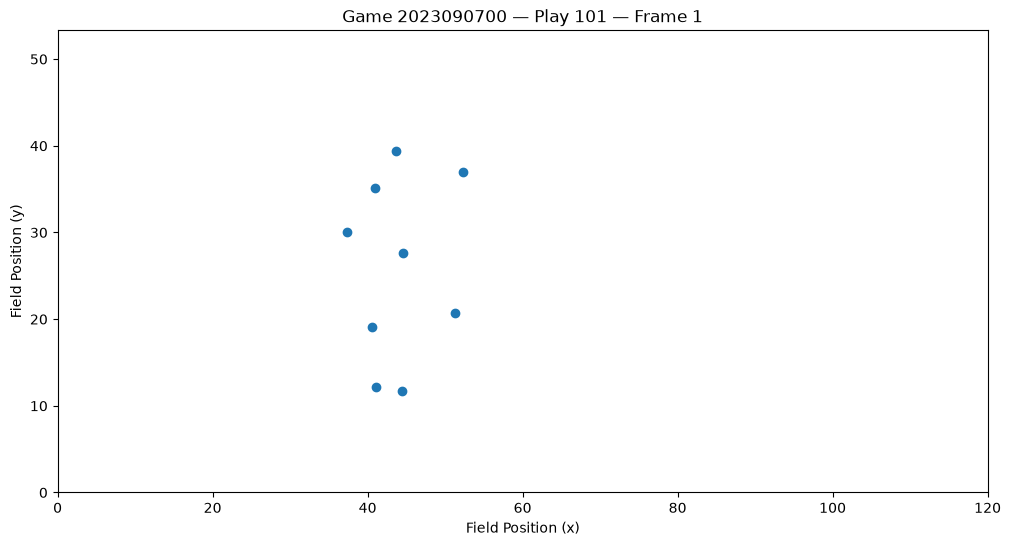

In [9]:
#Frame Animation attempt.
#Basically: 
#Frame 1 : Plot players
#Frame 2 : Plot players
#...
#Frame N : Plot players
#Plot all frames for a given game and frame. 
#We'll add player role and direction after and any other relevant variables. Then I'll see
#whats interesting.
#I'll need the animation tool from mpl. Import that. Its called FuncAnimation.

fig, ax = mpl.subplots(figsize=(12, 6))
#subplots returns fig, ax

ax.set_xlim(0, 120)
ax.set_ylim(0, 53.3)

ax.set_xlabel("Field Position (x)")
ax.set_ylabel("Field Position (y)")
ax.set_title("Game 2023090700 — Play 101")

#create animation function
def update(givenframe):

    ax.clear()

    # Get players at this frame
    frame = play[play["frame_id"] == givenframe]

    # Plot players
    ax.scatter(
        frame["x"],
        frame["y"]
    )

    # Keep the field dimensions consistent
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 53.3)

    ax.set_xlabel("Field Position (x)")
    ax.set_ylabel("Field Position (y)")
    ax.set_title(f"Game 2023090700 — Play 101 — Frame {givenframe}")

#Tell mpl what frames to use.
givenframe = sorted(play["frame_id"].unique()) ##remeber that play is already filtered via game and play id.
#Is frame_id included, does game id and play_id have frame_id? can you use play['x']
#for the sorted?

ani = FuncAnimation(
    fig,
    update,
    frames=givenframe,
    interval=100
)

from IPython.display import HTML

HTML(ani.to_jshtml())

#Diagnose. 6 players missing in frame 27. This is a data problem. See why.








In [13]:
play[play["frame_id"].isin([26, 27, 28])].groupby("frame_id")["nfl_id"].nunique()



frame_id
26    9
27    3
28    3
Name: nfl_id, dtype: int64

In [ ]:
#Further EDA
#create a function, take play id, plot where every player started, and show line/curve for play. 
#Figure out route style. Some players are good route runner/speed player? How to quantify that?
#typology of routes.
#play id  : 101


